# Exploratory Data Analysis and Insights on Air Quality Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to clean and explore environmental time-series data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Identifying and handling missing values
- Combining date and time columns
- Selecting, filtering, and sorting observations
- Calculating descriptive statistics
- Grouping records by month and hour
- Creating time-based and categorical columns
- Examining correlations
- Creating basic time-series visualizations
- Exporting cleaned data


## About the Dataset

The **AirQuality.csv** dataset contains **9,357 hourly observations** recorded by an air-quality monitoring device in an Italian city from March 2004 to April 2005.

It contains **15 columns**:

| Column | Description |
|---|---|
| `date`, `time` | Date and time of the observation |
| `co_gt` | Reference carbon monoxide concentration |
| `pt08_s1_co` | Sensor response associated with carbon monoxide |
| `nmhc_gt` | Reference non-methane hydrocarbon concentration |
| `benzene_gt` | Reference benzene concentration |
| `pt08_s2_nmhc` | Sensor response associated with non-methane hydrocarbons |
| `nox_gt` | Reference nitrogen oxides concentration |
| `pt08_s3_nox` | Sensor response associated with nitrogen oxides |
| `no2_gt` | Reference nitrogen dioxide concentration |
| `pt08_s4_no2` | Sensor response associated with nitrogen dioxide |
| `pt08_s5_o3` | Sensor response associated with ozone |
| `temperature_c` | Temperature in degrees Celsius |
| `relative_humidity` | Relative humidity percentage |
| `absolute_humidity` | Absolute humidity |

### Important Observation

The original data uses `-200` to represent missing readings. These markers have been converted to standard blank CSV values so Pandas will recognize them as `NaN`. The source's decimal commas and dotted time values were also converted into standard formats without changing the measurements.

Some pollutant columns contain many missing values. For this assignment, `df_clean` will remove only rows missing the three weather measurements, while Pandas will ignore remaining missing values during most calculations.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/360/air+quality)  
**License:** CC BY 4.0 for research use; review the repository terms before other uses.


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will handle incomplete sensor data, create timestamps, compare measurements across months and hours, and visualize changes over time.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **AirQuality.csv** into a DataFrame named `df`.


In [23]:
import pandas as pd
df = pd.read_csv('D:\Liha-Tech Assignments\Pandas\Air Quality\AirQuality.csv')

### Question 2
Display the first **5 rows** of the dataset.


In [24]:
df.head()

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


### Question 3
Display the last **5 rows** of the dataset.


In [25]:
df.tail()

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity
9352,04/04/2005,10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13:00:00,2.1,1003.0,NaN,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139
9356,04/04/2005,14:00:00,2.2,1071.0,NaN,11.9,1047.0,265.0,654.0,168.0,1129.0,816.0,28.5,13.1,0.5028


### Question 4
Find the total number of **rows and columns** in the dataset.


In [26]:
df.shape

(9357, 15)

### Question 5
Display all the **column names** in the dataset.


In [27]:
df.columns

Index(['date', 'time', 'co_gt', 'pt08_s1_co', 'nmhc_gt', 'benzene_gt',
       'pt08_s2_nmhc', 'nox_gt', 'pt08_s3_nox', 'no2_gt', 'pt08_s4_no2',
       'pt08_s5_o3', 'temperature_c', 'relative_humidity',
       'absolute_humidity'],
      dtype='str')

### Question 6
Display the **data type of each column**.


In [28]:
df.dtypes

date                     str
time                     str
co_gt                float64
pt08_s1_co           float64
nmhc_gt              float64
benzene_gt           float64
pt08_s2_nmhc         float64
nox_gt               float64
pt08_s3_nox          float64
no2_gt               float64
pt08_s4_no2          float64
pt08_s5_o3           float64
temperature_c        float64
relative_humidity    float64
absolute_humidity    float64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               9357 non-null   str    
 1   time               9357 non-null   str    
 2   co_gt              7674 non-null   float64
 3   pt08_s1_co         8991 non-null   float64
 4   nmhc_gt            914 non-null    float64
 5   benzene_gt         8991 non-null   float64
 6   pt08_s2_nmhc       8991 non-null   float64
 7   nox_gt             7718 non-null   float64
 8   pt08_s3_nox        8991 non-null   float64
 9   no2_gt             7715 non-null   float64
 10  pt08_s4_no2        8991 non-null   float64
 11  pt08_s5_o3         8991 non-null   float64
 12  temperature_c      8991 non-null   float64
 13  relative_humidity  8991 non-null   float64
 14  absolute_humidity  8991 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.1 MB


## 2. Missing Values and Date-Time Preparation

### Question 8
Display the number of **missing values in each column**.


In [30]:
df.isnull().sum()

date                    0
time                    0
co_gt                1683
pt08_s1_co            366
nmhc_gt              8443
benzene_gt            366
pt08_s2_nmhc          366
nox_gt               1639
pt08_s3_nox           366
no2_gt               1642
pt08_s4_no2           366
pt08_s5_o3            366
temperature_c         366
relative_humidity     366
absolute_humidity     366
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [31]:
df.isnull().sum().sum()

np.int64(16701)

### Question 10
Display every row that contains **at least one missing value**.


In [32]:
df[df.isna().any(axis=1)]

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity
9,11/03/2004,03:00:00,0.6,1010.0,19.0,1.7,561.0,NaN,1705.0,NaN,1235.0,501.0,10.3,60.2,0.7517
10,11/03/2004,04:00:00,NaN,1011.0,14.0,1.3,527.0,21.0,1818.0,34.0,1197.0,445.0,10.1,60.5,0.7465
33,12/03/2004,03:00:00,0.8,889.0,21.0,1.9,574.0,NaN,1680.0,NaN,1187.0,512.0,7.0,62.3,0.6261
34,12/03/2004,04:00:00,NaN,831.0,10.0,1.1,506.0,21.0,1893.0,32.0,1134.0,384.0,6.1,65.9,0.6248
39,12/03/2004,09:00:00,NaN,1545.0,NaN,22.1,1353.0,NaN,767.0,NaN,2058.0,1588.0,9.2,56.2,0.6561
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13:00:00,2.1,1003.0,NaN,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139


### Question 11
Create a DataFrame named `df_clean` by removing rows missing `temperature_c`, `relative_humidity`, or `absolute_humidity`. Display its shape.


In [33]:
df_clean = df.dropna(subset=['temperature_c', 'relative_humidity', 'absolute_humidity'])
df_clean.shape


(8991, 15)

### Question 12
Combine the `date` and `time` columns into a new datetime column named **datetime** using `pd.to_datetime()` with `dayfirst=True`.


In [34]:
df['datetime'] = pd.to_datetime(df['date']+ ' '+df['time'],dayfirst=True)

## 3. Selecting Rows and Columns

### Question 13
Select and display only the **temperature_c** column from `df_clean`.


In [35]:
df_clean['temperature_c']

0       13.6
1       13.3
2       11.9
3       11.0
4       11.2
        ... 
9352    21.9
9353    24.3
9354    26.9
9355    28.3
9356    28.5
Name: temperature_c, Length: 8991, dtype: float64

### Question 14
Select and display the **datetime, co_gt, nox_gt, no2_gt, temperature_c, and relative_humidity** columns.


In [36]:
df[['datetime','co_gt','nox_gt','no2_gt','temperature_c','relative_humidity']]

,datetime,co_gt,nox_gt,no2_gt,temperature_c,relative_humidity
0,2004-03-10 18:00:00,2.6,166.0,113.0,13.6,48.9
1,2004-03-10 19:00:00,2.0,103.0,92.0,13.3,47.7
2,2004-03-10 20:00:00,2.2,131.0,114.0,11.9,54.0
3,2004-03-10 21:00:00,2.2,172.0,122.0,11.0,60.0
4,2004-03-10 22:00:00,1.6,131.0,116.0,11.2,59.6
...,...,...,...,...,...,...
9352,2005-04-04 10:00:00,3.1,472.0,190.0,21.9,29.3
9353,2005-04-04 11:00:00,2.4,353.0,179.0,24.3,23.7
9354,2005-04-04 12:00:00,2.4,293.0,175.0,26.9,18.3
9355,2005-04-04 13:00:00,2.1,235.0,156.0,28.3,13.5


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns**.


In [37]:
df.iloc[:5,:6]

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5


### Question 16
Using `loc`, display rows **10 to 15** for the columns **datetime, co_gt, benzene_gt, temperature_c, and relative_humidity**.


In [38]:
df.loc[10:15,['datetime','co_gt','benzene_gt','temperature_c','relative_humidity']]

,datetime,co_gt,benzene_gt,temperature_c,relative_humidity
10,2004-03-11 04:00:00,NaN,1.3,10.1,60.5
11,2004-03-11 05:00:00,0.7,1.1,11.0,56.2
12,2004-03-11 06:00:00,0.7,1.6,10.5,58.1
13,2004-03-11 07:00:00,1.1,3.2,10.2,59.6
14,2004-03-11 08:00:00,2.0,8.0,10.8,57.4
15,2004-03-11 09:00:00,2.2,9.5,10.5,60.6


## 4. Descriptive Statistics and Measurement Coverage

### Question 17
Display descriptive statistics for the numeric columns using `describe()`.


In [39]:
df.describe()

,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000,9357
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530,2004-09-21 16:00:00
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,2004-03-10 18:00:00
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800,2004-06-16 05:00:00
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400,2004-09-21 16:00:00
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700,2004-12-28 03:00:00
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,2005-04-04 14:00:00
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813,NaN


### Question 18
Display the **earliest and latest datetime values** in `df_clean`.


In [41]:
df_clean['datetime'] = pd.to_datetime(df_clean['date']+ ' '+df_clean['time'],dayfirst=True)
df_clean['datetime'].min()
df_clean['datetime'].max()

Timestamp('2005-04-04 14:00:00')

### Question 19
Find the **minimum, maximum, and mean temperature**.


In [42]:
df['temperature_c'].agg(['min','max','mean'])

min     -1.900000
max     44.600000
mean    18.317829
Name: temperature_c, dtype: float64

### Question 20
Calculate the **mean relative humidity**.


In [44]:
df['relative_humidity'].mean()

np.float64(49.2342008675342)

### Question 21
Count the number of non-missing readings in the **co_gt** and **nmhc_gt** columns.


In [46]:
df['co_gt'].value_counts()
df['nmhc_gt'].value_counts()

nmhc_gt
66.0     14
29.0      9
40.0      9
88.0      8
93.0      8
         ..
344.0     1
265.0     1
365.0     1
642.0     1
501.0     1
Name: count, Length: 429, dtype: int64

### Question 22
Display the record with the **highest no2_gt value**.


In [48]:
df.loc[df['no2_gt'].idxmax()]

date                          11/02/2005
time                            16:00:00
co_gt                                7.1
pt08_s1_co                           NaN
nmhc_gt                              NaN
benzene_gt                           NaN
pt08_s2_nmhc                         NaN
nox_gt                            1218.0
pt08_s3_nox                          NaN
no2_gt                             340.0
pt08_s4_no2                          NaN
pt08_s5_o3                           NaN
temperature_c                        NaN
relative_humidity                    NaN
absolute_humidity                    NaN
datetime             2005-02-11 16:00:00
Name: 8110, dtype: object

## 5. Filtering and Sorting

### Question 23
Display all observations where **temperature_c is greater than 30°C**.


In [49]:
df[df['temperature_c']>30]

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
1029,22/04/2004,15:00:00,NaN,1165.0,NaN,17.5,1225.0,NaN,824.0,NaN,1676.0,1028.0,30.8,16.4,0.7167,2004-04-22 15:00:00
1030,22/04/2004,16:00:00,NaN,1224.0,NaN,19.1,1270.0,NaN,806.0,NaN,1739.0,1113.0,31.3,16.2,0.7262,2004-04-22 16:00:00
1292,03/05/2004,14:00:00,1.4,998.0,NaN,10.0,977.0,74.0,947.0,69.0,1496.0,695.0,30.3,20.1,0.8539,2004-05-03 14:00:00
1293,03/05/2004,15:00:00,1.5,1058.0,NaN,11.2,1023.0,81.0,896.0,74.0,1580.0,795.0,30.9,19.7,0.8649,2004-05-03 15:00:00
1294,03/05/2004,16:00:00,2.4,1203.0,NaN,16.8,1204.0,129.0,790.0,102.0,1744.0,1079.0,30.2,20.5,0.8672,2004-05-03 16:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4703,22/09/2004,17:00:00,5.0,1424.0,NaN,27.3,1486.0,506.0,523.0,218.0,2084.0,1537.0,32.2,28.8,1.3624,2004-09-22 17:00:00
4725,23/09/2004,15:00:00,2.6,1215.0,NaN,15.1,1150.0,282.0,608.0,118.0,1733.0,1115.0,30.4,37.2,1.5880,2004-09-23 15:00:00
4726,23/09/2004,16:00:00,3.2,1330.0,NaN,18.9,1264.0,323.0,586.0,146.0,1860.0,1362.0,31.5,34.9,1.5903,2004-09-23 16:00:00
4727,23/09/2004,17:00:00,4.6,1446.0,NaN,25.2,1434.0,442.0,522.0,190.0,2075.0,1619.0,31.6,34.8,1.5925,2004-09-23 17:00:00


### Question 24
Display observations where **relative_humidity is greater than 80%**.


In [50]:
df[df['relative_humidity']>80]

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
20,11/03/2004,14:00:00,2.9,1371.0,164.0,11.5,1034.0,207.0,983.0,128.0,1730.0,1037.0,8.0,81.1,0.8736,2004-03-11 14:00:00
299,23/03/2004,05:00:00,0.3,834.0,19.0,0.6,459.0,13.0,1908.0,22.0,1212.0,361.0,8.8,80.5,0.9147,2004-03-23 05:00:00
334,24/03/2004,16:00:00,2.7,1390.0,230.0,11.4,1028.0,197.0,829.0,126.0,1730.0,1002.0,9.6,81.1,0.9720,2004-03-24 16:00:00
348,25/03/2004,06:00:00,0.6,893.0,46.0,1.4,540.0,43.0,1604.0,51.0,1268.0,413.0,7.6,83.2,0.8695,2004-03-25 06:00:00
681,08/04/2004,03:00:00,0.8,890.0,63.0,3.3,672.0,NaN,1183.0,NaN,1338.0,781.0,7.6,80.6,0.8437,2004-04-08 03:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9168,27/03/2005,18:00:00,1.6,1153.0,NaN,4.4,734.0,272.0,712.0,122.0,1324.0,811.0,13.8,83.5,1.3154,2005-03-27 18:00:00
9169,27/03/2005,19:00:00,1.8,1220.0,NaN,5.7,796.0,285.0,652.0,121.0,1367.0,896.0,13.9,83.6,1.3208,2005-03-27 19:00:00
9170,27/03/2005,20:00:00,2.1,1218.0,NaN,6.3,825.0,307.0,627.0,126.0,1393.0,978.0,14.2,82.3,1.3219,2005-03-27 20:00:00
9171,27/03/2005,21:00:00,1.9,1172.0,NaN,6.0,810.0,237.0,637.0,115.0,1376.0,964.0,14.1,81.4,1.3046,2005-03-27 21:00:00


### Question 25
Display observations where **co_gt is greater than 5**.


In [51]:
df[df['co_gt']>5]

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
25,11/03/2004,19:00:00,6.9,1776.0,461.0,27.4,1488.0,383.0,702.0,172.0,2333.0,1704.0,9.7,69.3,0.8319,2004-03-11 19:00:00
26,11/03/2004,20:00:00,6.1,1640.0,401.0,24.0,1404.0,351.0,743.0,165.0,2191.0,1654.0,9.6,67.8,0.8133,2004-03-11 20:00:00
50,12/03/2004,20:00:00,6.6,1843.0,488.0,32.6,1610.0,340.0,624.0,170.0,2390.0,1887.0,12.9,50.5,0.7478,2004-03-12 20:00:00
53,12/03/2004,23:00:00,5.4,1677.0,367.0,21.8,1346.0,300.0,741.0,134.0,2062.0,1657.0,9.7,64.6,0.7771,2004-03-12 23:00:00
98,14/03/2004,20:00:00,5.9,1898.0,341.0,23.1,1381.0,325.0,681.0,173.0,2103.0,1905.0,17.6,46.1,0.9210,2004-03-14 20:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9097,24/03/2005,19:00:00,5.9,1726.0,NaN,30.8,1570.0,659.0,359.0,200.0,2021.0,1947.0,20.1,43.2,1.0051,2005-03-24 19:00:00
9098,24/03/2005,20:00:00,7.5,1818.0,NaN,35.5,1675.0,847.0,330.0,232.0,2143.0,2129.0,18.8,49.1,1.0538,2005-03-24 20:00:00
9121,25/03/2005,19:00:00,5.7,1673.0,NaN,27.2,1484.0,649.0,397.0,196.0,2008.0,1812.0,19.4,56.3,1.2500,2005-03-25 19:00:00
9122,25/03/2005,20:00:00,5.5,1605.0,NaN,23.7,1397.0,604.0,420.0,189.0,1891.0,1710.0,18.8,58.3,1.2514,2005-03-25 20:00:00


### Question 26
Using `query()`, display observations where **benzene_gt is greater than 20** and **nox_gt is greater than 200**.


In [52]:
df.query('benzene_gt >20 and nox_gt >200')

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
24,11/03/2004,18:00:00,4.8,1581.0,307.0,20.8,1319.0,281.0,799.0,151.0,2083.0,1409.0,10.3,64.2,0.8065,2004-03-11 18:00:00
25,11/03/2004,19:00:00,6.9,1776.0,461.0,27.4,1488.0,383.0,702.0,172.0,2333.0,1704.0,9.7,69.3,0.8319,2004-03-11 19:00:00
26,11/03/2004,20:00:00,6.1,1640.0,401.0,24.0,1404.0,351.0,743.0,165.0,2191.0,1654.0,9.6,67.8,0.8133,2004-03-11 20:00:00
50,12/03/2004,20:00:00,6.6,1843.0,488.0,32.6,1610.0,340.0,624.0,170.0,2390.0,1887.0,12.9,50.5,0.7478,2004-03-12 20:00:00
51,12/03/2004,21:00:00,4.4,1598.0,333.0,20.1,1299.0,274.0,752.0,149.0,1941.0,1627.0,12.1,53.3,0.7536,2004-03-12 21:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9121,25/03/2005,19:00:00,5.7,1673.0,NaN,27.2,1484.0,649.0,397.0,196.0,2008.0,1812.0,19.4,56.3,1.2500,2005-03-25 19:00:00
9122,25/03/2005,20:00:00,5.5,1605.0,NaN,23.7,1397.0,604.0,420.0,189.0,1891.0,1710.0,18.8,58.3,1.2514,2005-03-25 20:00:00
9206,29/03/2005,08:00:00,5.1,1519.0,NaN,26.3,1461.0,623.0,370.0,140.0,2005.0,1648.0,14.4,65.8,1.0727,2005-03-29 08:00:00
9253,31/03/2005,07:00:00,4.0,1531.0,NaN,23.6,1394.0,673.0,407.0,133.0,1860.0,1683.0,12.7,69.6,1.0206,2005-03-31 07:00:00


### Question 27
Sort `df_clean` by **temperature_c in descending order** and display the first 10 rows.


In [54]:
df_clean.sort_values(by='temperature_c',ascending=False).head(10)

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
3214,22/07/2004,16:00:00,2.3,1186.0,NaN,15.1,1151.0,166.0,680.0,157.0,1686.0,1235.0,44.6,12.6,1.1684,2004-07-22 16:00:00
3213,22/07/2004,15:00:00,2.1,1158.0,NaN,14.3,1126.0,153.0,693.0,143.0,1654.0,1150.0,44.3,13.0,1.1830,2004-07-22 15:00:00
3215,22/07/2004,17:00:00,2.8,1261.0,NaN,18.6,1258.0,179.0,629.0,170.0,1813.0,1315.0,43.4,14.8,1.2882,2004-07-22 17:00:00
3237,23/07/2004,15:00:00,1.5,1080.0,NaN,12.3,1059.0,107.0,733.0,123.0,1622.0,908.0,43.1,13.8,1.1803,2004-07-23 15:00:00
3165,20/07/2004,15:00:00,NaN,1127.0,NaN,14.0,1117.0,158.0,714.0,132.0,1625.0,1092.0,42.8,12.3,1.0326,2004-07-20 15:00:00
3212,22/07/2004,14:00:00,1.5,1079.0,NaN,11.1,1019.0,108.0,749.0,113.0,1559.0,929.0,42.8,14.3,1.2003,2004-07-22 14:00:00
3238,23/07/2004,16:00:00,1.8,1085.0,NaN,13.2,1091.0,130.0,723.0,129.0,1638.0,1010.0,42.8,13.8,1.1681,2004-07-23 16:00:00
3190,21/07/2004,16:00:00,NaN,1105.0,NaN,10.2,984.0,97.0,767.0,106.0,1532.0,868.0,42.7,14.4,1.2092,2004-07-21 16:00:00
2851,07/07/2004,13:00:00,2.2,1068.0,NaN,15.1,1152.0,193.0,739.0,142.0,1683.0,1309.0,42.6,9.6,0.8012,2004-07-07 13:00:00
2852,07/07/2004,14:00:00,2.2,1090.0,NaN,14.1,1120.0,195.0,743.0,130.0,1629.0,1283.0,42.5,10.2,0.8478,2004-07-07 14:00:00


### Question 28
Display the **5 observations with the highest no2_gt readings**.


In [55]:
df.sort_values(by='no2_gt',ascending=False).head(5)

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime
8110,11/02/2005,16:00:00,7.1,NaN,NaN,NaN,NaN,1218.0,NaN,340.0,NaN,NaN,NaN,NaN,NaN,2005-02-11 16:00:00
7913,03/02/2005,11:00:00,3.5,1312.0,NaN,15.5,1164.0,790.0,570.0,333.0,1230.0,1761.0,8.5,39.7,0.4425,2005-02-03 11:00:00
8111,11/02/2005,17:00:00,6.6,NaN,NaN,NaN,NaN,1227.0,NaN,326.0,NaN,NaN,NaN,NaN,NaN,2005-02-11 17:00:00
7912,03/02/2005,10:00:00,4.9,1429.0,NaN,20.7,1317.0,947.0,495.0,322.0,1425.0,1916.0,5.1,50.8,0.4499,2005-02-03 10:00:00
8109,11/02/2005,15:00:00,6.1,NaN,NaN,NaN,NaN,1054.0,NaN,312.0,NaN,NaN,NaN,NaN,NaN,2005-02-11 15:00:00


## 6. Grouping and Aggregation

### Question 29
Calculate the **average temperature for each month number** using the `datetime` column.


In [59]:
df.groupby(df['datetime'].dt.month)['temperature_c'].mean()

datetime
1      8.222694
2      7.113591
3     13.695850
4     16.785128
5     20.281233
6     26.476540
7     29.419112
8     29.130360
9     24.620370
10    20.497577
11    13.485417
12    11.140813
Name: temperature_c, dtype: float64

### Question 30
Calculate the **average co_gt reading for each hour of the day**.


In [61]:
df.groupby(df['datetime'].dt.hour)['co_gt'].mean()

datetime
0     1.786018
1     1.467802
2     1.099063
3     0.888462
4     0.758659
5     0.712934
6     0.921562
7     1.810903
8     2.823750
9     2.972477
10    2.565749
11    2.260923
12    2.169632
13    2.201227
14    2.126074
15    2.049231
16    2.267477
17    2.816314
18    3.436336
19    3.733234
20    3.469069
21    2.600904
22    1.976970
23    1.877508
Name: co_gt, dtype: float64

### Question 31
Calculate the monthly averages of **co_gt, benzene_gt, nox_gt, and no2_gt**.


In [62]:
df.groupby(df['datetime'].dt.month)[['co_gt','benzene_gt','nox_gt','no2_gt']].mean()

,co_gt,benzene_gt,nox_gt,no2_gt
datetime,,,,
1,2.135059,9.024597,349.819718,134.781690
2,2.096229,7.500839,315.043614,160.694704
3,2.144079,9.219393,243.184275,123.285831
4,2.142931,9.708333,145.638743,98.710297
5,1.940034,10.219041,122.132107,93.148829
6,1.900000,10.595748,122.064715,94.084877
7,1.784946,10.599462,126.754213,104.120956
8,1.280084,6.993669,75.868526,70.097804
9,2.164209,11.554558,280.572072,108.047297


### Question 32
For each hour of the day, calculate the **minimum, maximum, and mean temperature** using `agg()`.


In [63]:
df.groupby(df['datetime'].dt.hour)['temperature_c'].agg(['min','max','mean'])

,min,max,mean
datetime,,,
0,0.2,29.8,16.108065
1,0.0,28.4,15.723797
2,-0.1,28.3,15.285867
3,-1.1,28.8,14.836702
4,-1.4,28.9,14.436605
5,-1.3,27.5,14.187268
6,-1.2,27.5,13.986968
7,-1.3,27.6,14.284043
8,-1.9,29.0,15.201596


### Question 33
Determine which month number has the **highest average no2_gt reading**.


In [64]:
df.groupby(df['datetime'].dt.month)['no2_gt'].mean().sort_values(ascending=False)

datetime
2     160.694704
1     134.781690
12    124.411576
3     123.285831
11    122.531915
9     108.047297
7     104.120956
4      98.710297
6      94.084877
5      93.148829
10     89.775194
8      70.097804
Name: no2_gt, dtype: float64

## 7. Creating and Modifying Columns

### Question 34
Create a new column named **month** from `datetime` using the `.dt` accessor.


In [66]:
df['month'] = df['datetime'].dt.month
df

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime,month
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00,3
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00,3
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00,3
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00,3
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568,2005-04-04 10:00:00,4
9353,04/04/2005,11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119,2005-04-04 11:00:00,4
9354,04/04/2005,12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406,2005-04-04 12:00:00,4
9355,04/04/2005,13:00:00,2.1,1003.0,NaN,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139,2005-04-04 13:00:00,4


### Question 35
Create a new column named **hour** from `datetime` using the `.dt` accessor.


In [68]:
df['hour'] = df['datetime'].dt.hour
df

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime,month,hour
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00,3,18
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00,3,19
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00,3,20
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00,3,21
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00,3,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568,2005-04-04 10:00:00,4,10
9353,04/04/2005,11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119,2005-04-04 11:00:00,4,11
9354,04/04/2005,12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406,2005-04-04 12:00:00,4,12
9355,04/04/2005,13:00:00,2.1,1003.0,NaN,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139,2005-04-04 13:00:00,4,13


### Question 36
Create a column named **temperature_level** using `apply()` with a `lambda` function. Store `Warm` when `temperature_c` is greater than or equal to 25; otherwise store `Cool`.


In [70]:
df['temperature_level'] = df['temperature_c'].apply(lambda x:'Warm' if x>=25 else 'Cool')
df

,date,time,co_gt,pt08_s1_co,nmhc_gt,benzene_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity,absolute_humidity,datetime,month,hour,temperature_level
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00,3,18,Cool
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00,3,19,Cool
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00,3,20,Cool
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00,3,21,Cool
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00,3,22,Cool
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568,2005-04-04 10:00:00,4,10,Cool
9353,04/04/2005,11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119,2005-04-04 11:00:00,4,11,Cool
9354,04/04/2005,12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406,2005-04-04 12:00:00,4,12,Warm
9355,04/04/2005,13:00:00,2.1,1003.0,NaN,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139,2005-04-04 13:00:00,4,13,Warm


## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **co_gt, benzene_gt, nox_gt, no2_gt, temperature_c, and relative_humidity**.


In [72]:
df[['co_gt', 'benzene_gt', 'nox_gt', 'no2_gt', 'temperature_c', 'relative_humidity']].corr()



,co_gt,benzene_gt,nox_gt,no2_gt,temperature_c,relative_humidity
co_gt,1.000000,0.931078,0.795028,0.683343,0.022109,0.048890
benzene_gt,0.931078,1.000000,0.718839,0.614474,0.198956,-0.061681
nox_gt,0.795028,0.718839,1.000000,0.763111,-0.269683,0.221032
no2_gt,0.683343,0.614474,0.763111,1.000000,-0.186533,-0.091759
temperature_c,0.022109,0.198956,-0.269683,-0.186533,1.000000,-0.578621
relative_humidity,0.048890,-0.061681,0.221032,-0.091759,-0.578621,1.000000


### Question 38
Create a **line chart** showing the daily average temperature over time.


<Axes: xlabel='datetime'>

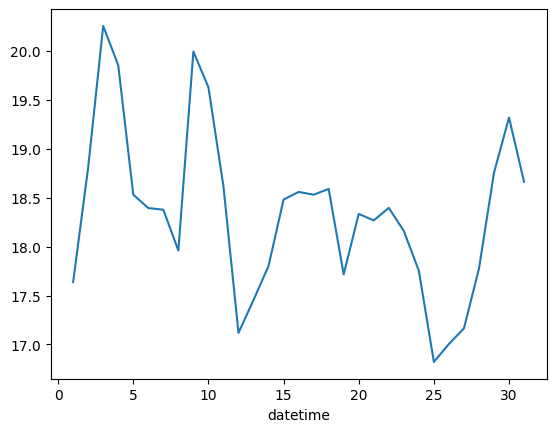

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt
a= df.groupby(df['datetime'].dt.day)['temperature_c'].mean()
sns.lineplot(x=a.index , y=a.values)

### Question 39
Create a **histogram** of the non-missing `co_gt` readings with an appropriate title and axis labels.


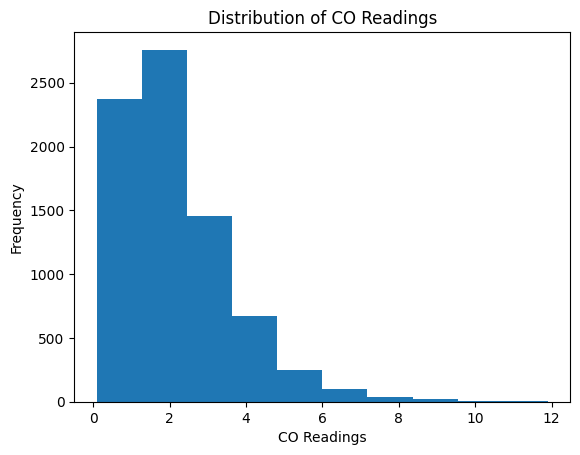

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.hist( df['co_gt'].dropna())
plt.title('Distribution of CO Readings')
plt.xlabel('CO Readings')
plt.ylabel('Frequency')
plt.show()

### Question 40
Save `df_clean` as **AirQuality_Cleaned.csv** using `to_csv()` without saving the index.


In [79]:
df_clean.to_csv('AirQuality_cleaned.csv',index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with incomplete time-series data, datetime operations, grouped summaries, and basic environmental visualizations before moving to forecasting or predictive modeling.
